# Task 3: Cross-dataset generalization (KDEF -> FER2013)

**Pre-Requisite**: 
- `figures/task1_test_results.csv`) from 1st notebook
- `models/task2_kdef_best_model_configs.pkl` from 2nd notebook


We take the best configuration from Task 2 (HOG + SVM, chosen by subject-grouped cross-validation on KDEF), retrain it on all 980 frontal KDEF images and test it directly on the full FER2013 dataset (35,887 images). Both datasets are brought into the same format, 48x48 grayscale with pixel values in [0, 1], and use the same HOG parameters. We compare it with the same configuration on KDEF itself (Task 2) and with the FER-trained model on FER (Task 1).

The report asks the following questions
- What adaptations were needed?
- What is domain shift? 
- Why does performance degrade?
- Which features transfer best?

## Variable Initialization

In [3]:
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import pickle

sys.path.append(os.path.abspath(".."))   # repository root, as an absolute path
os.chdir("..")                           # so the detector file is found during the import
from src.preprocess import preprocess_kdef_image
os.chdir("notebooks")                    # back to the notebook folder


## Variables for KDEF dataset
ROOT_DIR = Path.cwd().parent

KDEF_DIR = Path(ROOT_DIR / "data/KDEF")
KDEF_EMOTIONS = {
    "AF": "afraid",
    "AN": "angry",
    "DI": "disgust",
    "HA": "happy",
    "NE": "neutral",
    "SA": "sad",
    "SU": "surprise",
}
KDEF_POSES = {
    "FL": "full_left",
    "HL": "half_left",
    "S":  "straight",
    "HR": "half_right",
    "FR": "full_right",
}

KDEF_EMOTION_LABELS = KDEF_EMOTIONS.values()


## Variables for FER dataset
FER_DIR = Path(ROOT_DIR / "data/fer/")
FER_EMOTION_DICT = {
    0:'0: Angry',
    1:'1: Disgust',
    2:'2: Fear',
    3:'3: Happy',
    4:'4: Sad',
    5:'5: Surprise',
    6:'6: Neutral'
}
FER_EMOTION_LABELS = [emot.split(": ")[1] for emot in FER_EMOTION_DICT.values()]
# print(FER_EMOTION_LABELS)

MODEL_DIR = Path(ROOT_DIR / "models/")


## 1. Load both datasets in the common FER format

To compare the two datasets, every image needs to look like a FER image: 48x48 pixels, grayscale, with values between 0 and 1. FER2013 is already in this format, so we only rescale the pixel values. The KDEF photos are larger colour images, so `src/preprocess.py` first finds the face, adds a 20% margin around it, and then converts the crop to grayscale, resizes it to 48x48 and rescales it.

From KDEF we keep only the frontal photos (`S`): 70 people, each photographed in 2 sessions with 7 emotions, for 980 images in total. Since the model is tested on FER, all 980 are used for training.

Once that is complete, we perform HOG feature extraction with the same params used in task 1 and 2, and fit the SVM model with the parameters that had the best cross validation score in task 2.

In [4]:
def load_kdef_into_dataframe():
    records = []
    for img_path in KDEF_DIR.rglob("*.JPG"):
        stem = img_path.stem
        acquisition = stem[0]   # A or B
        subject = stem[1:4]     # F01, M12, ...
        found = False

        for emotion_code in KDEF_EMOTIONS:

            if stem[4:].startswith(emotion_code):

                pose_code = stem[4+len(emotion_code):]

                if pose_code not in KDEF_POSES:
                    continue

                records.append({
                    "path": str(img_path),
                    "acquisition": acquisition,
                    "subject": subject,
                    "emotion": KDEF_EMOTIONS[emotion_code],
                    "pose": KDEF_POSES[pose_code],
                })


                found = True
                break

        if not found:
            print("Skipping:", stem)
    df = pd.DataFrame(records)
    return df

kdef_df = load_kdef_into_dataframe()
kdef_df = kdef_df[kdef_df["pose"] == "straight"]

Skipping: AM31H
Skipping: AF31V


In [5]:
kdef_x_train = []
kdef_y_train = []
for _, row in kdef_df.iterrows():
    try:
        img = preprocess_kdef_image(
            row["path"]
        )

        kdef_x_train.append(img)
        kdef_y_train.append(row["emotion"])
    except Exception as e:
        print(e)


kdef_x_train = np.array(kdef_x_train)
kdef_y_train = np.array(kdef_y_train)


In [6]:
from feature_extraction import extract_hog_kdef

hog_kdef_x_train = extract_hog_kdef(kdef_x_train)

In [7]:
from sklearn.base import clone
import joblib

task2 = pd.read_pickle(MODEL_DIR / "task2_kdef_best_model_configs.pkl")
display(task2[["model", "params", "mean_test_accuracy", "mean_test_balanced_accuracy", "mean_test_macro_f1"]].round(3))

best_task2_model_description = task2.loc[task2["mean_test_macro_f1"].idxmax()]
display(best_task2_model_description)

best_task2_model = clone(best_task2_model_description["estimator"]).fit(hog_kdef_x_train, kdef_y_train)
joblib.dump(best_task2_model, MODEL_DIR / "task3_kdef_hog_svm.pkl")

,model,params,mean_test_accuracy,mean_test_balanced_accuracy,mean_test_macro_f1
0,LogisticRegression,"{'model__C': 0.01, 'scaler': PowerTransformer()}",0.674,0.674,0.669
1,SVM,"{'model__C': 10.0, 'model__gamma': 0.0001, 'mo...",0.686,0.686,0.679
2,RandomForest,"{'model__max_depth': 10, 'model__min_samples_l...",0.628,0.628,0.611


model                                                                        SVM
params                         {'model__C': 10.0, 'model__gamma': 0.0001, 'mo...
estimator                      (PowerTransformer(), SVC(C=10.0, gamma=0.0001,...
mean_test_accuracy                                                      0.686039
mean_test_balanced_accuracy                                             0.686039
mean_test_macro_f1                                                      0.678805
Name: 1, dtype: object

['/Users/vikramchandrasekaran/Documents/TUEindhoven/DataAnalysisAndLearningMethods/Assignment2/ml-emotionalrecognition/models/task3_kdef_hog_svm.pkl']

In [9]:
# Full FER2013 dataset in one file
fer_full = pd.read_csv(FER_DIR / "fer2013.csv")
fer_full_img = np.stack([np.array(p.split(), dtype=np.uint8).reshape(48, 48) for p in fer_full["pixels"]]).astype(np.float32) / 255
y_fer_full = fer_full["emotion"].values

# Same HOG extractor as for KDEF
hog_fer_full = extract_hog_kdef(fer_full_img)

print("FER full dataset:", hog_fer_full.shape)

FER full dataset: (35887, 900)


### KDEF -> FER: evaluate the KDEF-trained model on the full FER dataset

The model has never seen a FER image, so the whole FER2013 dataset is going to be the test bed. We extract HOG features from FER with the same function as for KDEF and map the KDEF label names to FER's integer labels (eg. "afraid" becomes "Fear").

For comparison:
- KDEF -> KDEF: the Task 2 cross-validation score of the same configuration, i.e. how well it does on KDEF people it has not seen.
- FER -> FER: the Task 1 model (HOG + SVM trained on FER) on FER PrivateTest

In [15]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

# KDEF labels are strings, FER labels are integers 0..6
KDEF_TO_FER_LABEL = {"angry": 0, "disgust": 1, "afraid": 2, "happy": 3, "sad": 4, "surprise": 5, "neutral": 6}

def compute_scores(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
    }

# 1. KDEF -> FER: predict every FER image, then convert the KDEF label names to FER labels
y_pred_fer_full = np.array([KDEF_TO_FER_LABEL[label] for label in best_task2_model.predict(hog_fer_full)])
kdef_to_fer = compute_scores(y_fer_full, y_pred_fer_full)
kdef_to_fer.update({"Scenario": "KDEF -> FER"})

# 2. KDEF -> KDEF: cross-validation score of the same configuration on KDEF (Task 2)
kdef_to_kdef = {
    "Scenario": "KDEF -> KDEF",
    "accuracy": best_task2_model_description["mean_test_accuracy"],
    "balanced_accuracy": best_task2_model_description["mean_test_balanced_accuracy"],
    "macro_f1": best_task2_model_description["mean_test_macro_f1"],
}

# 3. FER -> FER: the FER-trained model on FER PrivateTest (Task 1)
task1_test = pd.read_csv(ROOT_DIR / "figures/task1_test_results.csv").iloc[0]
fer_to_fer = {
    "Scenario": "FER -> FER",
    "accuracy": task1_test["accuracy"],
    "balanced_accuracy": task1_test["balanced_accuracy"],
    "macro_f1": task1_test["macro_f1"],
}

# One row per setting
kdef_to_fer_results = pd.DataFrame([kdef_to_fer, kdef_to_kdef, fer_to_fer]).set_index("Scenario")
display(kdef_to_fer_results.round(3))

,accuracy,balanced_accuracy,macro_f1
Scenario,,,
KDEF -> FER,0.225,0.215,0.195
KDEF -> KDEF,0.686,0.686,0.679
FER -> FER,0.574,0.549,0.568


KDEF -> FER (HOG + SVM)
              precision    recall  f1-score   support

       Angry      0.167     0.212     0.187      4953
     Disgust      0.020     0.146     0.036       547
        Fear      0.155     0.220     0.182      5121
       Happy      0.560     0.287     0.380      8989
         Sad      0.200     0.310     0.243      6077
    Surprise      0.310     0.316     0.313      4002
     Neutral      0.325     0.012     0.024      6198

    accuracy                          0.225     35887
   macro avg      0.248     0.215     0.195     35887
weighted avg      0.310     0.225     0.227     35887



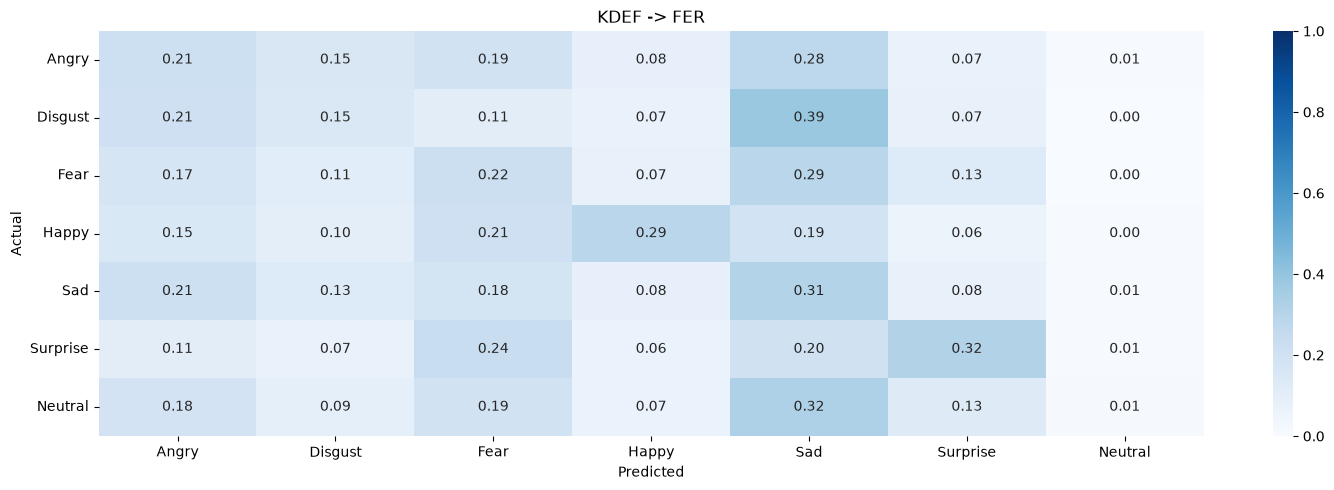

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

FIG_DIR = ROOT_DIR / "figures"

print("KDEF -> FER (HOG + SVM)")
print(classification_report(y_fer_full, y_pred_fer_full, target_names=FER_EMOTION_LABELS, digits=3))

fig, axes = plt.subplots(1, 1, figsize=(15,5))

# Row-normalised confusion matrix on the full FER dataset
cm = confusion_matrix(y_fer_full, y_pred_fer_full, labels=range(7), normalize="true")
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, xticklabels=FER_EMOTION_LABELS, yticklabels=FER_EMOTION_LABELS)
axes.set_title("KDEF -> FER")
axes.set_xlabel("Predicted")
axes.set_ylabel("Actual")


plt.tight_layout()
plt.savefig(FIG_DIR / "task3_kdef_to_fer_confusion_matrix.png", dpi=150)
plt.show()

kdef_to_fer_results.to_csv(FIG_DIR / "task3_kdef_to_fer_results.csv", index_label="setting")

## 2. Domain shift between KDEF and FER

The KDEF -> FER scores are far below both same-domain references. In this section we look at how the two datasets differ.

### 2.1 Imbalanced dataset

KDEF is perfectly balanced, with 140 images per emotion. FER is not: about 25% of its images are Happy and only 1.5% are Disgust. A model trained on KDEF has no idea that some emotions are much more common than others, and plain accuracy on FER is dominated by the large classes. That is why we also report balanced accuracy and macro-F1.

,FER full,KDEF
Angry,13.802,14.286
Disgust,1.524,14.286
Fear,14.270,14.286
Happy,25.048,14.286
Sad,16.934,14.286
Surprise,11.152,14.286
Neutral,17.271,14.286


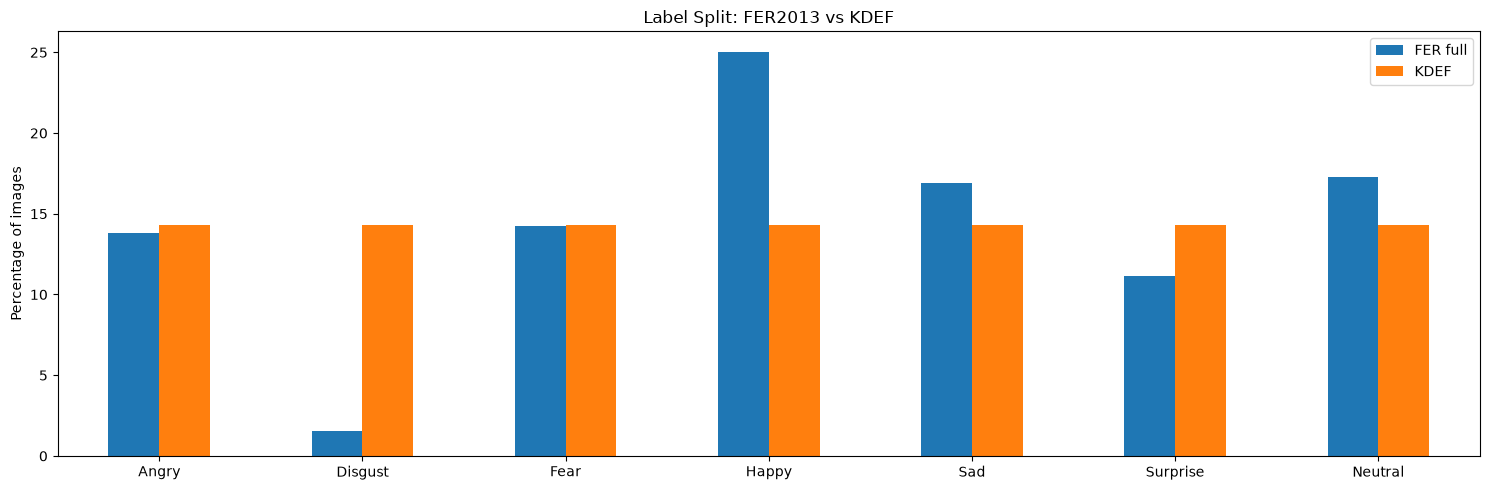

In [18]:
RANDOM_STATE = 42

# KDEF labels as FER integers, so both datasets use the same encoding
kdef_y_train_fer = np.array([KDEF_TO_FER_LABEL[label] for label in kdef_y_train])

priors = pd.DataFrame({
    "FER full": np.bincount(y_fer_full, minlength=7) / len(y_fer_full)*100,
    "KDEF": np.bincount(kdef_y_train_fer, minlength=7) / len(kdef_y_train_fer)*100,
}, index=FER_EMOTION_LABELS)
display(priors.round(3))

ax = priors.plot.bar(figsize=(15,5), rot=0)
ax.set_ylabel("Percentage of images")
ax.set_title("Label Split: FER2013 vs KDEF")
plt.tight_layout()
plt.savefig(FIG_DIR / "task3_label_split.png", dpi=150)
plt.show()

### 2.2 How different are the images in the dataset?

Though images from both the datasets are  48x48 and grayscale, the images per emotion are very different. The images in the FER dataset does not have any consistency in the environment where the photo is captured, where as KDEF have ensure to have the same angle, margin around the face, background etc. Therefore, the same emotion look very different in each dataset

#### Random example comparison per emotion

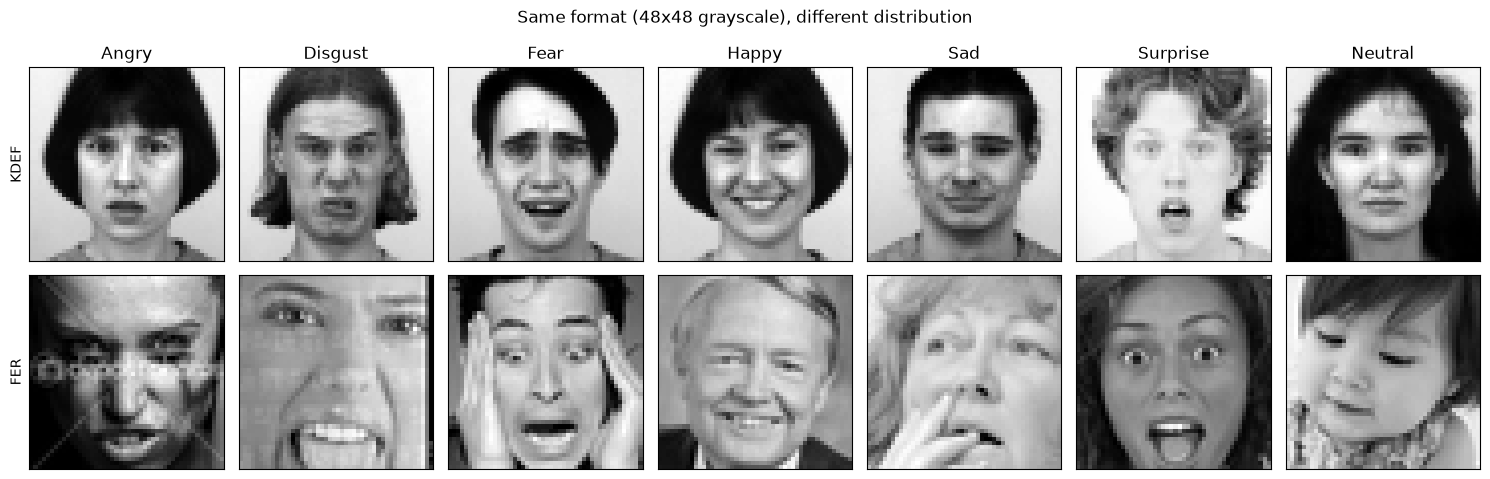

In [19]:
# One random example per emotion: KDEF in the top row, FER in the bottom row
rng = np.random.RandomState(RANDOM_STATE)
fig, axes = plt.subplots(2, 7, figsize=(15, 5))

for k, emotion in enumerate(FER_EMOTION_LABELS):
    kdef_example = kdef_x_train[rng.choice(np.where(kdef_y_train_fer == k)[0])]
    fer_example = fer_full_img[rng.choice(np.where(y_fer_full == k)[0])]

    axes[0, k].imshow(kdef_example, cmap='gray')
    axes[1, k].imshow(fer_example, cmap='gray')
    axes[0, k].set_title(emotion)

# Hide the pixel ticks, but keep the row labels on the left
for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])
axes[0, 0].set_ylabel("KDEF")
axes[1, 0].set_ylabel("FER")

plt.suptitle("Same format (48x48 grayscale), different distribution")
plt.tight_layout()
plt.savefig(FIG_DIR / "task3_samples_kdef_vs_fer.png", dpi=150)
plt.show()

#### Brightness and Contrast per pixel comparison

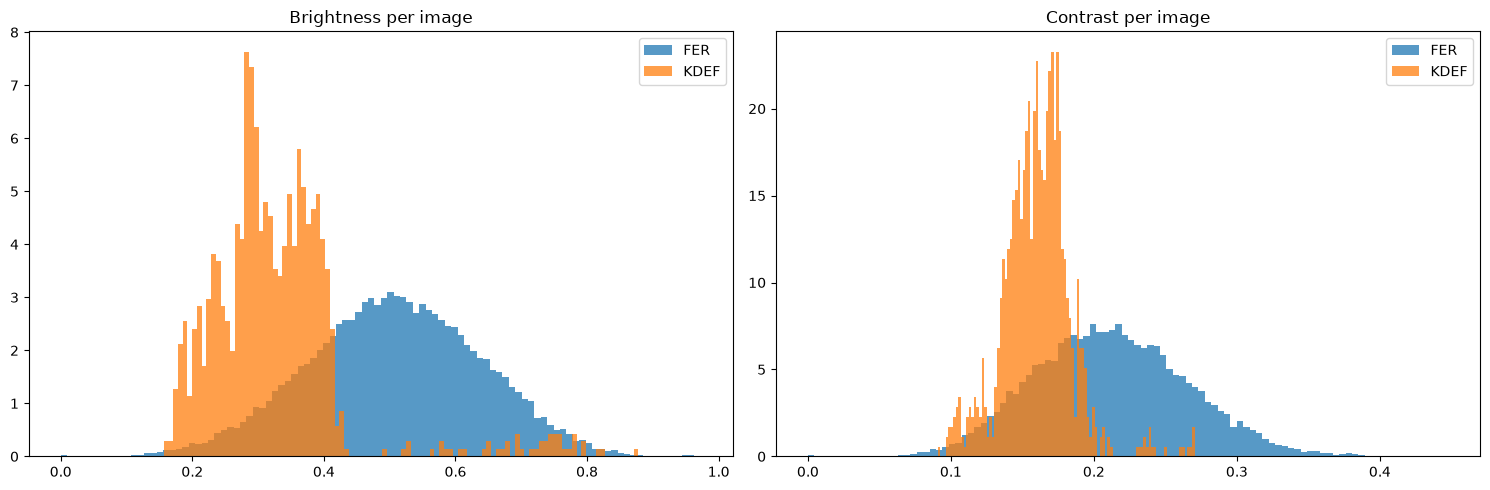

,brightness mean,brightness std,contrast mean,contrast std
FER full,0.507,0.131,0.212,0.054
KDEF,0.327,0.106,0.161,0.024


In [28]:
# Brightness = mean pixel value per image, contrast = standard deviation of the pixels per image
fer_brightness = fer_full_img.reshape(len(fer_full_img), -1).mean(axis=1)
fer_contrast = fer_full_img.reshape(len(fer_full_img), -1).std(axis=1)
kdef_brightness = kdef_x_train.reshape(len(kdef_x_train), -1).mean(axis=1)
kdef_contrast = kdef_x_train.reshape(len(kdef_x_train), -1).std(axis=1)



fig, axes = plt.subplots(1, 2, figsize=(15,5))
axes[0].hist(fer_brightness, bins=100, density=True, alpha=0.75, label="FER")
axes[0].hist(kdef_brightness, bins=100, density=True, alpha=0.75, label="KDEF")
axes[0].set_title("Brightness per image")
axes[0].legend()

axes[1].hist(fer_contrast, bins=100, density=True, alpha=0.75, label="FER")
axes[1].hist(kdef_contrast, bins=100, density=True, alpha=0.75, label="KDEF")
axes[1].set_title("Contrast per image")
axes[1].legend()

plt.tight_layout()
plt.savefig(FIG_DIR / "task3_brightness_and_contrast.png", dpi=150)
plt.show()

display(pd.DataFrame({
    "brightness mean": [fer_brightness.mean(), kdef_brightness.mean()],
    "brightness std": [fer_brightness.std(), kdef_brightness.std()],
    "contrast mean": [fer_contrast.mean(), kdef_contrast.mean()],
    "contrast std": [fer_contrast.std(), kdef_contrast.std()],
}, index=["FER full", "KDEF"]).round(3))

#### Mean face per emotion

This is to see if the position of each feature of a face are in the same coordinates across all the images in the dataset. The more blurry the face is, it is a sign of inconsistency of feature coordinates

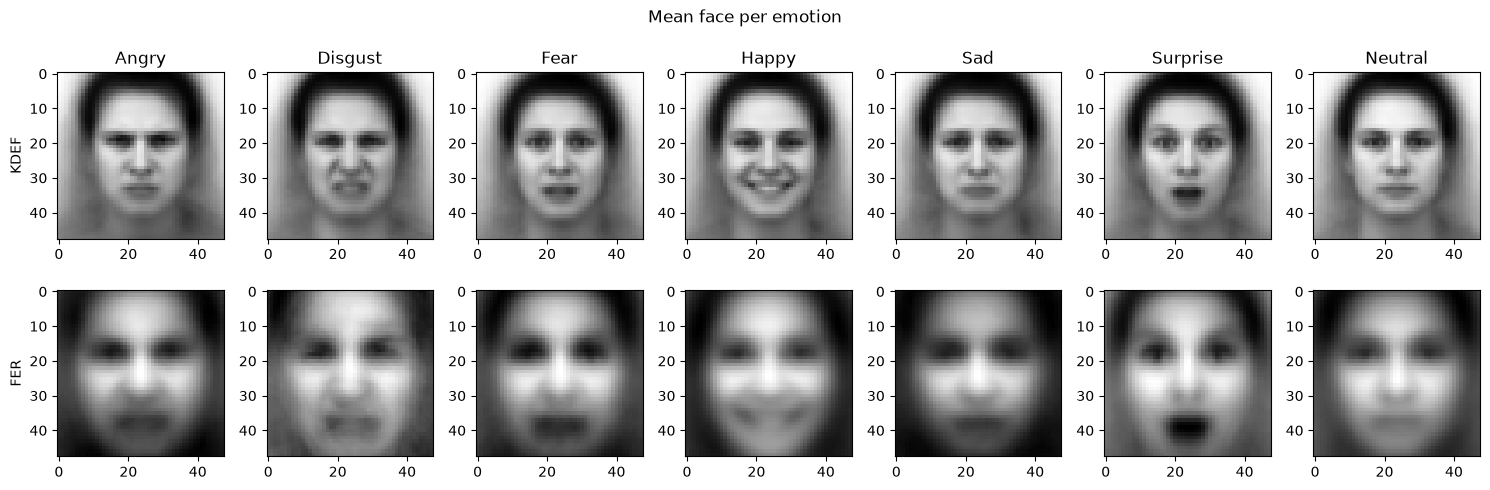

In [31]:
# Mean face per emotion
fig, axes = plt.subplots(2, len(FER_EMOTION_LABELS), figsize=(15,5))

for k, emotion in enumerate(FER_EMOTION_LABELS):
    kdef_emotion_face = kdef_x_train[kdef_y_train_fer == k].mean(axis=0)   
    fer_emotion_face = fer_full_img[y_fer_full == k].mean(axis=0)         

    axes[0, k].imshow(kdef_emotion_face, cmap="gray")
    axes[1, k].imshow(fer_emotion_face, cmap="gray")
    axes[0, k].set_title(emotion)

axes[0, 0].set_ylabel("KDEF")
axes[1, 0].set_ylabel("FER")

plt.suptitle("Mean face per emotion")
plt.tight_layout()
plt.savefig(FIG_DIR / "task3_mean_face_per_emotion.png", dpi=150)
plt.show()

### 2.3 Can a model tell FER and KDEF images apart?

To check whether the datasets also differ in the HOG features the model uses, we ignore the emotions and train a classifier to predict which dataset an image comes from. We use all 980 KDEF images and 980 FER images with the same emotion mix (140 per emotion), and evaluate a logistic regression on the HOG features with 5-fold cross-validation

In [13]:
# Step 1: sample FER images with the same number of images per emotion as KDEF (140 each)
rng = np.random.RandomState(RANDOM_STATE)
fer_sample_idx = []
for k in range(7):
    n_kdef_images = np.sum(kdef_y_train_fer == k)
    fer_images_of_emotion = np.where(y_fer_full == k)[0]
    random_choice_fer_images = rng.choice(fer_images_of_emotion, n_kdef_images, replace=False)
    fer_sample_idx.extend(random_choice_fer_images)

print("FER images sampled:", len(fer_sample_idx), " KDEF images:", len(hog_kdef_x_train))

FER images sampled: 980  KDEF images: 980


In [14]:
# Step 2: put the FER sample and KDEF together
hog_fer_sample = hog_fer_full[fer_sample_idx]

X_both = np.vstack([hog_fer_sample, hog_kdef_x_train])                       # HOG features of all 1960 images
y_both = np.array([0] * len(hog_fer_sample) + [1] * len(hog_kdef_x_train))   # 0 = FER, 1 = KDEF

In [ ]:
# Step 3: train a logistic regression to predict "FER or KDEF?" and score it with 5-fold cross-validation
# (5 times: train on 4/5 of the images, test on the other 1/5)
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

which_dataset_clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
scores = cross_val_score(which_dataset_clf, X_both, y_both, cv=5, scoring="accuracy")
print(f"Balanced accuracy for dataset classifier: {scores.mean():.3f} ")

Balanced accuracy for 'FER or KDEF?': 0.988 


## 3. Which emotions transfer?

We compare the F1 score of each emotion on KDEF with its F1 score on FER. An emotion transfers well if its score stays about the same on FER.

Since the model was trained on all KDEF images, there is no KDEF test set left. Instead we use cross-validation grouped by person: the 70 people are split into 5 groups, a model is trained on 4 groups and predicts the 5th, and this repeats until every KDEF image has a prediction from a model that never saw that person.

In [33]:
# Step 1: predict every KDEF image with a model that never saw that person (5-fold CV, grouped by subject)
from sklearn.model_selection import GroupKFold, cross_val_predict

kdef_subjects = kdef_df["subject"].to_numpy()                    # one subject per image, same order as kdef_x_train
kdef_cv_model = clone(best_task2_model_description["estimator"])  # same configuration as the main model, untrained
y_pred_kdef_cv = cross_val_predict(kdef_cv_model, hog_kdef_x_train, kdef_y_train,
                                   groups=kdef_subjects, cv=GroupKFold(n_splits=5))

# KDEF string labels -> FER integer labels, like the FER predictions
y_pred_kdef_cv = np.array([KDEF_TO_FER_LABEL[label] for label in y_pred_kdef_cv])

In [35]:
# Step 2: F1 score per emotion on KDEF (in-domain) and on FER (cross-domain)
f1_kdef = f1_score(kdef_y_train_fer, y_pred_kdef_cv, average=None)
f1_fer = f1_score(y_fer_full, y_pred_fer_full, average=None)

per_class_f1 = pd.DataFrame({"F1 on KDEF": f1_kdef, "F1 on FER": f1_fer}, index=FER_EMOTION_LABELS)

display(per_class_f1.round(2).sort_values("F1 on FER", ascending=False))
per_class_f1.to_csv(FIG_DIR / "task3_per_class_f1.csv")

,F1 on KDEF,F1 on FER
Happy,0.89,0.38
Surprise,0.71,0.31
Sad,0.50,0.24
Angry,0.66,0.19
Fear,0.46,0.18
Disgust,0.69,0.04
Neutral,0.66,0.02


### 3.1 Which FER images does the model get wrong?

Random sample of misclassified FER images, with their true and predicted emotion.

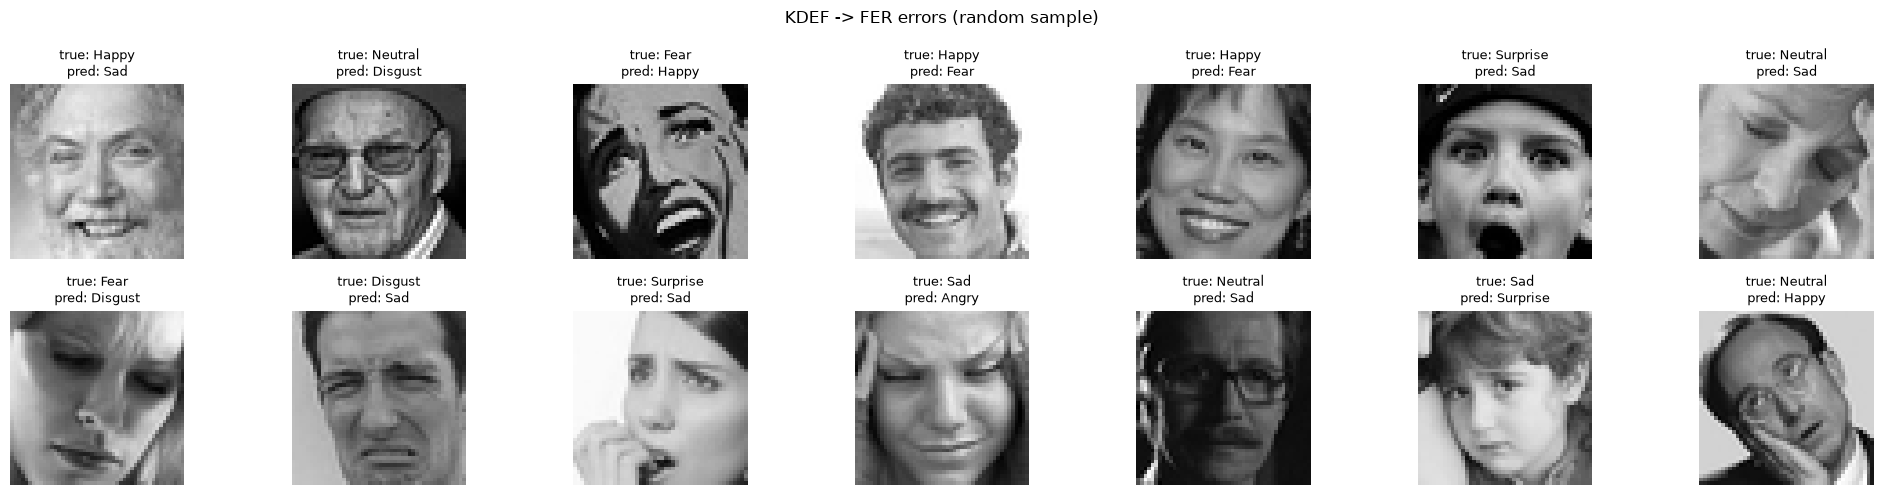

In [36]:
# Step 1: 14 random FER images that the model gets wrong
wrong_idx = np.where(y_pred_fer_full != y_fer_full)[0]
show_idx = np.random.RandomState(RANDOM_STATE).choice(wrong_idx, 14, replace=False)

fig, axes = plt.subplots(2, 7, figsize=(20, 5))
for ax, i in zip(axes.ravel(), show_idx):
    ax.imshow(fer_full_img[i], cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"true: {FER_EMOTION_LABELS[y_fer_full[i]]}\npred: {FER_EMOTION_LABELS[y_pred_fer_full[i]]}", fontsize=9)
    ax.axis("off")
plt.suptitle("KDEF -> FER errors (random sample)")
plt.tight_layout()
plt.savefig(FIG_DIR / "task3_kdef_to_fer_errors.png", dpi=150)
plt.show()

## 4. Which HOG features transfer best?

HOG splits the face into a 6x6 grid of 8x8-pixel squares and measures, for each square, how strong the edges are in 9 directions (0°, 20°, ..., 160°). Each of the 900 HOG values is the edge strength in one direction in one square. Squares are counted more than once because HOG uses overlapping 2x2 blocks: 5x5 blocks x 4 squares x 9 directions = 900.

A feature transfers well if it behaves the same on FER as on KDEF: if it is highest for Happy and lowest for Sad in KDEF, the same should hold in FER. We measure this as the correlation between the feature's average per emotion in the two datasets (+1 = same pattern, 0 = unrelated, -1 = opposite).

We list the features that transfer best and worst, and draw the score on the face, one value per square. Each feature is looked at on its own while the SVM combines all of them, so this shows where on the face the transferable information is rather than exactly what the SVM does.

In [58]:
# Step 1: Average of each HOG feature per emotion, in KDEF and in FER (7 emotions x 900 features)
kdef_avg = np.array([hog_kdef_x_train[kdef_y_train_fer == k].mean(axis=0) for k in range(7)])
fer_avg = np.array([hog_fer_full[y_fer_full == k].mean(axis=0) for k in range(7)])
print(f'Average HOG features of KDEF per emotion - {kdef_avg.shape}')
print(f'Average HOG features of FER per emotion - {fer_avg.shape}')

Average HOG features of KDEF per emotion - (7, 900)
Average HOG features of FER per emotion - (7, 900)


In [63]:
# Step 2: Correlation between KDEF and FER for each HOG feature
# Do the feature's ups and downs over the 7 emotions match? (+1 = same pattern, 0 = unrelated, -1 = opposite)
correlation_coefficients = []

for j in range(900):
    kdef_pattern = kdef_avg[:, j]   # this feature's average for each of the 7 emotions in KDEF
    fer_pattern = fer_avg[:, j]     # the same in FER
    correlation_coefficients.append(np.corrcoef(kdef_pattern, fer_pattern)[0, 1])

In [64]:
# Step 3: Face location of each HOG feature, and the features that transfer best and worst
# 900 = 5 x 5 blocks x 2 x 2 squares per block x 9 edge directions
block_row, block_col, row_in_block, col_in_block, direction = np.unravel_index(np.arange(900), (5, 5, 2, 2, 9))

hog_features = pd.DataFrame({
    "row": block_row + row_in_block,    # square in the 6 x 6 grid: 0 = top, 5 = bottom
    "col": block_col + col_in_block,    # 0 = left, 5 = right
    "edge direction (deg)": direction * 20,
    "Correlation Coefficient": correlation_coefficients,
})
hog_features.to_csv(FIG_DIR / "task3_hog_feature_scores.csv", index=False)

print("Features that transfer best:")
display(hog_features.sort_values("Correlation Coefficient", ascending=False).head(10).round(2))
print("Features that transfer worst:")
display(hog_features.sort_values("Correlation Coefficient").head(10).round(2))

Features that transfer best:


,row,col,edge direction (deg),Correlation Coefficient
847,5,3,20,0.95
472,2,3,80,0.95
661,3,4,80,0.94
803,4,3,40,0.93
804,4,3,60,0.93
310,2,3,80,0.93
610,4,2,140,0.92
668,4,3,40,0.92
251,2,2,160,0.92
452,3,2,40,0.92


Features that transfer worst:


,row,col,edge direction (deg),Correlation Coefficient
341,1,5,160,-0.88
891,5,5,0,-0.86
94,1,2,80,-0.84
746,5,0,160,-0.80
179,1,5,160,-0.78
588,3,2,60,-0.77
1,0,0,20,-0.76
541,3,0,20,-0.76
160,0,5,140,-0.75
563,4,0,100,-0.74


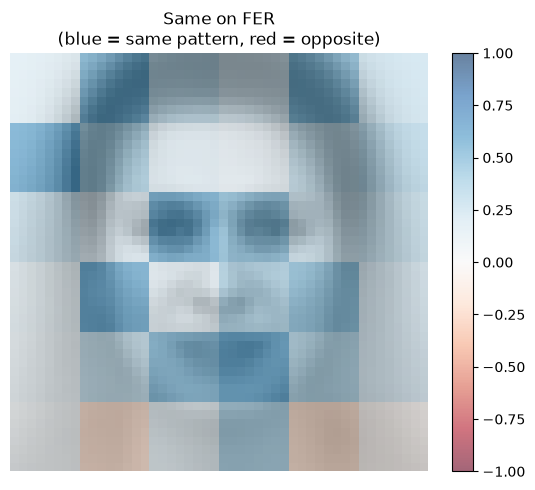

In [72]:
# Step 4: Correlation map on the face (average per square, drawn on the mean KDEF face)
same_grid = hog_features.groupby(["row", "col"])["Correlation Coefficient"].mean().unstack()   # 6 x 6 table, one value per square

plt.figure(figsize=(5.5, 5))
plt.imshow(kdef_mean_face, cmap="gray", extent=(0, 48, 48, 0))
plt.imshow(same_grid, cmap="RdBu", vmin=-1, vmax=1, alpha=0.6, extent=(0, 48, 48, 0))
plt.colorbar(fraction=0.046)
plt.title("Same on FER\n(blue = same pattern, red = opposite)")
plt.axis("off")
plt.tight_layout()
plt.savefig(FIG_DIR / "task3_hog_feature_transfer.png", dpi=150)
plt.show()

## 5. Notes for the report (draft, remove before submission)

Fill in the ▶ items from the outputs above.

**Adaptations needed**
- KDEF images were converted to the FER format: face detection, 20% margin, grayscale, 48x48, scaled to [0, 1]. FER images only needed scaling.
- Same HOG extractor and settings for both datasets.
- KDEF label names were mapped to FER's integer labels (afraid -> Fear). The seven classes match one to one.
- The Task 2 pipeline (PowerTransformer + RBF-SVM, C=10, gamma=1e-4) was retrained on all 980 KDEF images.
- Nothing was tuned or fitted on FER, including the scaler.

**Domain shift**

Training and test data come from different distributions, P_KDEF(x, y) ≠ P_FER(x, y). Three kinds play a role here:
- covariate shift, P(x): studio photos vs web images, with different lighting, pose, occlusion, crop and demographics (Sections 2.2 and 2.3);
- label shift, P(y): KDEF is balanced, FER is not (Section 2.1);
- concept shift, P(y|x): KDEF expressions are posed and exaggerated with reliable labels, FER expressions are often subtle with noisy labels.

**Why performance degrades**
- KDEF -> FER reaches accuracy 0.225, balanced accuracy 0.215 and macro-F1 0.195, against 0.679 macro-F1 on KDEF (Task 2) and 0.568 for the FER-trained model. Balanced accuracy is only about 0.07 above chance.
- The predictions don't match FER's class mix: Neutral is almost never predicted (recall 0.012) and Disgust is predicted far too often (precision 0.020).
- 980 frontal studio images of 70 people can't cover FER's variety of poses, lighting and image quality. ▶ error vs brightness/contrast (3.1).
- HOG compares fixed regions of the image, so faces at a different position or scale break it (mean faces in 2.2). ▶ domain classifier score (2.3).

**Which emotions transfer**
- Happy (F1 0.380) and Surprise (0.313) transfer best; both have clear mouth and eye shapes. Neutral (0.024) and Disgust (0.036) fail. ▶ compare with the KDEF scores and the "FER ratio" column (Section 3).

**Which features transfer**
- ▶ Within HOG (Section 4): which face regions keep the same emotion pattern on FER?
- ▶ Only HOG is tested here. Across feature types, either add a comparison or argue it: HOG is fairly robust to lighting but sensitive to alignment, pixel-based PCA picks up KDEF's lighting and identities, and landmarks ignore lighting but depend on finding the face reliably at 48x48.

**Limitations**
- One random seed; KDEF has a single pose and 70 people.
- The references use different images: Task 2 CV uses 56 KDEF people, the per-emotion CV in Section 3 uses all 70, and FER -> FER is on PrivateTest only.
- No domain adaptation was tried (e.g. aligning crops, histogram equalisation, training on both datasets); that could be part of Task 5.